# EDA ngày 14/11/2026 — AI4I 2020

Notebook phân tích dữ liệu nguồn `data/ai4i2020.csv` và kết quả lần chạy `results/2026-11-14_000052_127416`. Thống kê chất lượng mô tả toàn bộ nguồn; phân tích biến đầu vào chỉ dùng tập train theo split của lần chạy. Bảng mô hình chỉ đọc kết quả validation đã lưu. Không đánh giá mô hình trên test, không huấn luyện lại, và không diễn giải tương quan như quan hệ nhân quả.

In [1]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

search_paths = [Path.cwd(), *Path.cwd().parents]
search_paths += [path / "MachineLearning_Nhom" for path in search_paths]
ROOT = next(
    path for path in search_paths
    if (path / "ai4i").is_dir() and (path / "data" / "ai4i2020.csv").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ai4i.config import NUM, SEED
from ai4i.data import load_dataset

DATA_PATH = ROOT / "data" / "ai4i2020.csv"
RUN_DIR = ROOT / "results" / "2026-11-14_000052_127416"
TARGET = "Machine failure"
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

dataset = load_dataset(DATA_PATH)
df = dataset.frame
metadata = pd.read_json(RUN_DIR / "metadata.json", typ="series")
split = pd.read_csv(RUN_DIR / "split_indices.csv")
log = pd.read_csv(RUN_DIR / "experiment_log.csv")

data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert metadata["data_sha256"] == data_hash, "Hash dữ liệu không khớp lần chạy ngày 14/11."
assert set(split["split"]) == {"train", "validation", "test"}
assert not split["row_index"].duplicated().any()
assert set(split["row_index"]) == set(df.index)
assert log["evaluation_set"].eq("validation").all()
assert log["status"].eq("success").all()

split["row_index"] = split["row_index"].astype(int)
train_ids = split.loc[split["split"].eq("train"), "row_index"]
validation_ids = split.loc[split["split"].eq("validation"), "row_index"]
test_ids = split.loc[split["split"].eq("test"), "row_index"]
train = df.loc[train_ids].copy()

print(f"Dữ liệu: {DATA_PATH.relative_to(ROOT)} | SHA-256: {data_hash}")
print(f"Lần chạy: {RUN_DIR.name} | seed cấu hình: {SEED}")
print(f"Số dòng — train: {len(train_ids):,}; validation: {len(validation_ids):,}; test: {len(test_ids):,}")

Dữ liệu: data\ai4i2020.csv | SHA-256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
Lần chạy: 2026-11-14_000052_127416 | seed cấu hình: 42
Số dòng — train: 7,000; validation: 1,500; test: 1,500


## 1. Cấu trúc và chất lượng dữ liệu

`UDI` và `Product ID` là định danh; `Type` cùng năm biến số là đầu vào gốc. Các cờ mode chỉ dùng kiểm tra mô tả, không đưa vào đầu vào mô hình để tránh rò rỉ thông tin nhãn.

In [2]:
quality = pd.DataFrame([{
    "Số dòng": len(df),
    "Số cột": len(df.columns),
    "Ô thiếu": int(df.isna().sum().sum()),
    "Dòng trùng toàn bộ": int(df.duplicated().sum()),
    "UDI trùng": int(df["UDI"].duplicated().sum()),
    "Giá trị số không hữu hạn": int((~np.isfinite(df[NUM].to_numpy(dtype=float))).sum()),
}])
display(quality)

roles = pd.DataFrame({"Cột": df.columns})
roles["Vai trò"] = roles["Cột"].map(
    lambda col: "Nhãn mục tiêu" if col == TARGET else
    "Đầu vào" if col == "Type" or col in NUM else
    "Cờ mode — loại khỏi đầu vào" if col in MODES else
    "Định danh — loại khỏi đầu vào"
)
display(roles)

,Số dòng,Số cột,Ô thiếu,Dòng trùng toàn bộ,UDI trùng,Giá trị số không hữu hạn
0,10000,14,0,0,0,0


,Cột,Vai trò
0,UDI,Định danh — loại khỏi đầu vào
1,Product ID,Định danh — loại khỏi đầu vào
2,Type,Đầu vào
3,Air temperature [K],Đầu vào
4,Process temperature [K],Đầu vào
5,Rotational speed [rpm],Đầu vào
6,Torque [Nm],Đầu vào
7,Tool wear [min],Đầu vào
8,Machine failure,Nhãn mục tiêu
9,TWF,Cờ mode — loại khỏi đầu vào


## Nhận xét chất lượng

Nguồn có 10.000 dòng và 14 cột, không có ô thiếu, dòng trùng toàn bộ, UDI trùng hay giá trị số không hữu hạn. Sáu biến gốc được dùng làm đầu vào; định danh và cờ mode không đưa vào mô hình.

In [3]:
mismatch = df[TARGET].ne(df[MODES].max(axis=1))
mismatch_count = int(mismatch.sum())
print(f"Số nhãn Machine failure không khớp OR của các cờ mode: {mismatch_count}")
print("Các nhãn nguồn được giữ nguyên; phép đối chiếu này chỉ nhằm mô tả chất lượng.")
display(df.loc[mismatch, ["UDI", TARGET, *MODES]].head(10))

Số nhãn Machine failure không khớp OR của các cờ mode: 27
Các nhãn nguồn được giữ nguyên; phép đối chiếu này chỉ nhằm mô tả chất lượng.


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


## Nhận xét về nhãn

Có 27 quan sát mà `Machine failure` không khớp phép OR của năm cờ mode. Giữ nguyên nhãn nguồn và dùng các cờ chỉ để kiểm tra, không làm đầu vào.

## 2. Phân bố nhãn và các tập dữ liệu

Bảng split bên dưới chỉ mô tả kích thước và số trường hợp lỗi của từng phân hoạch; không chứa đánh giá mô hình trên test.

,Nhãn,Số mẫu,Tỷ lệ (%)
0,Không lỗi (0),9661,96.61
1,Lỗi (1),339,3.39


,Số mẫu,Số mẫu lỗi,Tỷ lệ lỗi (%)
split,,,
train,7000.0,237.0,3.385714
validation,1500.0,51.0,3.400000
test,1500.0,51.0,3.400000


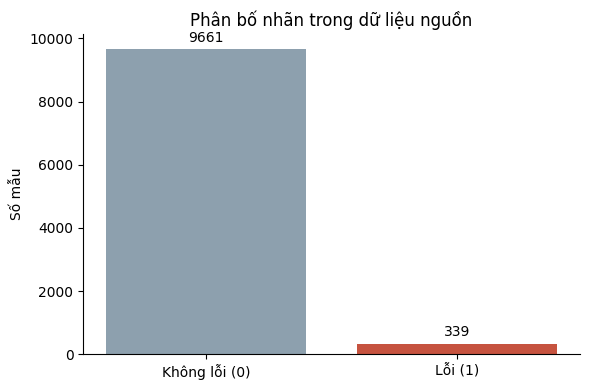

In [4]:
class_counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
class_table = pd.DataFrame({
    "Nhãn": ["Không lỗi (0)", "Lỗi (1)"],
    "Số mẫu": class_counts.to_numpy(),
    "Tỷ lệ (%)": (class_counts / len(df) * 100).to_numpy(),
})
display(class_table)

split_table = split.groupby("split", sort=False).apply(
    lambda part: pd.Series({
        "Số mẫu": len(part),
        "Số mẫu lỗi": int(df.loc[part["row_index"], TARGET].sum()),
        "Tỷ lệ lỗi (%)": float(df.loc[part["row_index"], TARGET].mean() * 100),
    }), include_groups=False
).reindex(["train", "validation", "test"])
display(split_table)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_table["Nhãn"], class_table["Số mẫu"], color=["#8da0ae", "#c6533f"])
ax.set(title="Phân bố nhãn trong dữ liệu nguồn", ylabel="Số mẫu")
ax.bar_label(bars, fmt="%d", padding=3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Nhận xét phân bố nhãn

Nguồn có 339 mẫu lỗi trên 10.000 mẫu (3,39%), nên accuracy đơn lẻ có thể gây hiểu nhầm. Train có 237 mẫu lỗi; validation và test mỗi tập có 51 mẫu lỗi. Số đếm của test chỉ mô tả phép chia, không phải kết quả đánh giá.

## 3. Thống kê biến số trên train

Thống kê và biểu đồ đặc trưng dưới đây chỉ dùng train, tránh dùng validation/test để rút ra mô tả đặc trưng.

In [5]:
display(train[NUM].describe().T)

group_stats = train.groupby(TARGET)[NUM].agg(["mean", "median"]).T
display(group_stats)

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],7000.0,300.014357,2.002674,295.3,298.3,300.1,301.5,304.5
Process temperature [K],7000.0,310.006629,1.481637,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],7000.0,1539.237429,180.237529,1168.0,1423.0,1504.0,1614.0,2886.0
Torque [Nm],7000.0,40.001300,10.006015,3.8,33.2,40.1,46.8,76.6
Tool wear [min],7000.0,107.623571,63.863906,0.0,52.0,107.0,163.0,253.0


Machine failure                           0            1
Air temperature [K]     mean     299.982109   300.934599
                        median   300.100000   301.600000
Process temperature [K] mean     309.995845   310.314346
                        median   310.000000   310.400000
Rotational speed [rpm]  mean    1540.362117  1507.143460
                        median  1507.000000  1365.000000
Torque [Nm]             mean      39.649874    50.029536
                        median    39.800000    53.300000
Tool wear [min]         mean     106.413130   142.164557
                        median   106.000000   166.000000

## Nhận xét thống kê biến số

Trên train, nhóm lỗi có trung vị mô-men 53,3 Nm và độ mòn 166 phút; nhóm không lỗi lần lượt là 39,8 Nm và 106 phút. Đây là khác biệt mô tả của mẫu này, không chứng minh nguyên nhân gây lỗi.

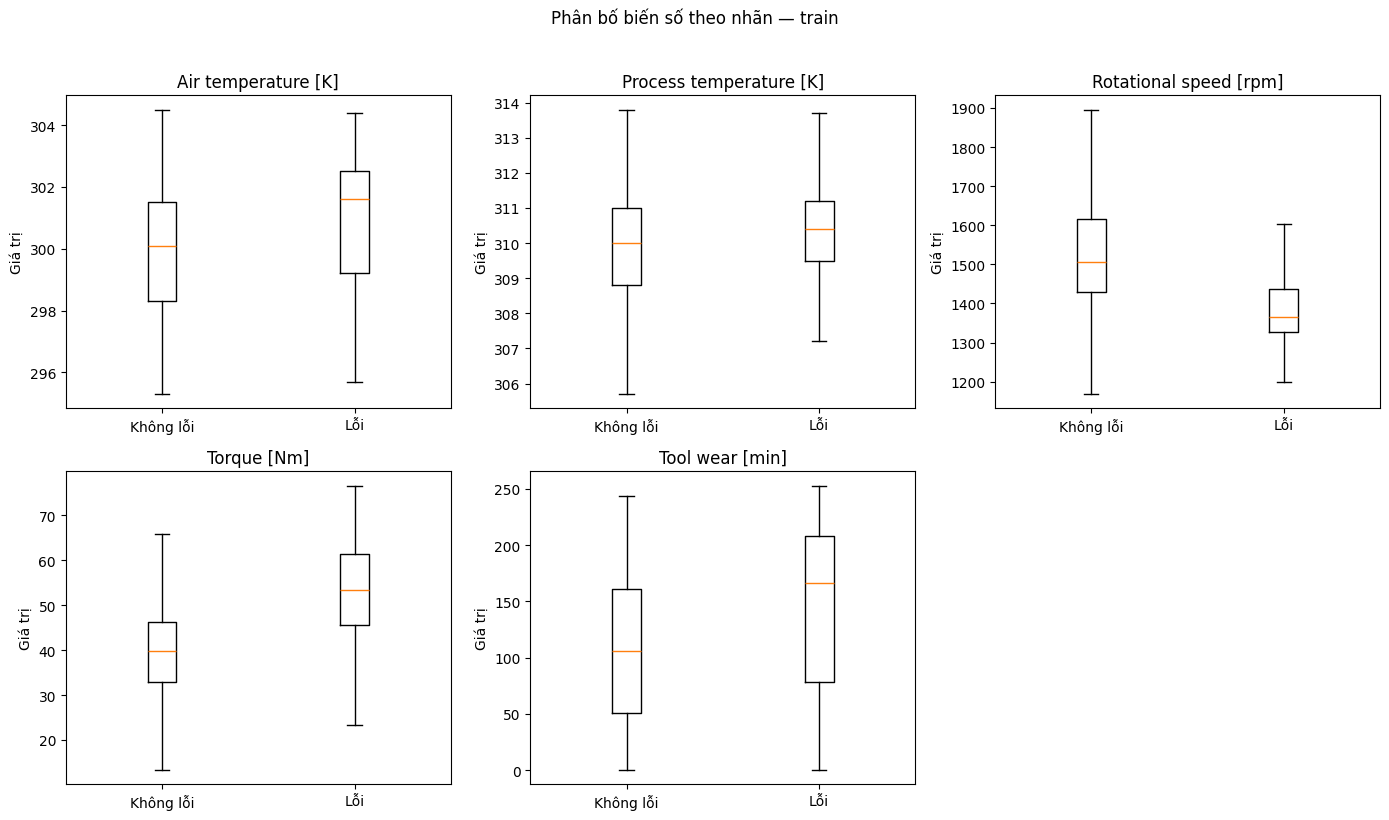

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for column, ax in zip(NUM, axes.flat):
    values = [train.loc[train[TARGET].eq(label), column] for label in (0, 1)]
    ax.boxplot(values, tick_labels=["Không lỗi", "Lỗi"], showfliers=False)
    ax.set_title(column)
    ax.set_ylabel("Giá trị")
axes.flat[-1].set_visible(False)
fig.suptitle("Phân bố biến số theo nhãn — train", y=1.02)
plt.tight_layout()
plt.show()

## Nhận xét biểu đồ hộp

Biểu đồ cho thấy phân bố của các nhóm có vùng chồng lấp; một biến đơn lẻ không tách hoàn toàn hai nhãn. Điểm ngoài râu được ẩn để dễ đọc hình, nhưng vẫn được giữ trong dữ liệu và các thống kê.

## 4. Tỷ lệ lỗi theo Type và tương quan biến số

Đây là thống kê mô tả trên train. Khác biệt quan sát được không chứng minh quan hệ nhân quả.

,Số mẫu,Số mẫu lỗi,Tỷ lệ lỗi (%)
Type,,,
H,705,14,1.985816
L,4217,175,4.149870
M,2078,48,2.309913


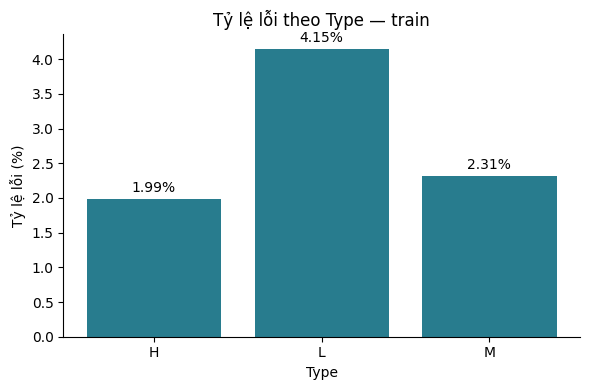

In [7]:
type_summary = train.groupby("Type")[TARGET].agg(
    so_mau="count", so_loi="sum", ty_le_loi="mean"
).sort_index()
type_summary["ty_le_loi_pct"] = type_summary.pop("ty_le_loi") * 100
display(type_summary.rename(columns={
    "so_mau": "Số mẫu", "so_loi": "Số mẫu lỗi", "ty_le_loi_pct": "Tỷ lệ lỗi (%)"
}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(type_summary.index, type_summary["ty_le_loi_pct"], color="#287c8e")
ax.set(title="Tỷ lệ lỗi theo Type — train", xlabel="Type", ylabel="Tỷ lệ lỗi (%)")
ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Nhận xét theo Type

Trên train, tỷ lệ lỗi quan sát được là L: 4,15% (175/4.217), M: 2,31% (48/2.078), H: 1,99% (14/705). Nhóm H có ít mẫu lỗi hơn, nên các tỷ lệ cần được hiểu trong bối cảnh cỡ mẫu.

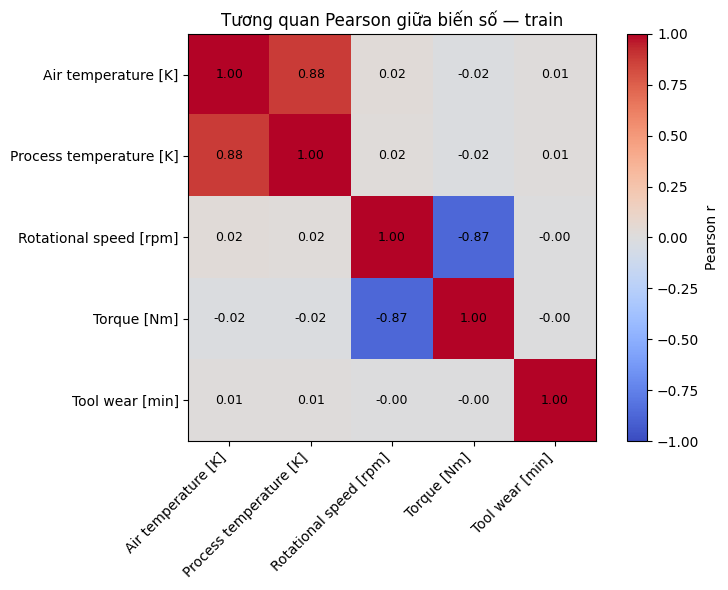

In [8]:
correlation = train[NUM].corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=45, ha="right")
ax.set_yticks(range(len(NUM)), NUM)
for row in range(len(NUM)):
    for col in range(len(NUM)):
        ax.text(col, row, f"{correlation.iloc[row, col]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Tương quan Pearson giữa biến số — train")
fig.colorbar(image, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

## Nhận xét quan hệ đặc trưng

Tương quan Pearson trên train giữa hai biến nhiệt độ khoảng 0,878; giữa tốc độ quay và mô-men khoảng -0,874. Các biến có thể liên hệ tuyến tính trong dữ liệu, nhưng tương quan không đồng nghĩa với quan hệ nhân quả.

## 5. Kết quả mô hình ngày 14/11

Các số liệu sau được đọc từ `experiment_log.csv` của lần chạy, đánh giá trên validation với ngưỡng dự đoán của giao thức hiện tại. F1/precision/recall là của lớp lỗi. Không dùng kết quả này để tuyên bố hiệu năng trên test hay dữ liệu ngoài.

In [9]:
metrics = log[[
    "run", "model", "precision", "recall", "f1", "roc_auc",
    "average_precision", "fn", "fp", "evaluation_set"
]].copy()
display(metrics.sort_values(["run", "f1"], ascending=[True, False]).round(4))

best_row = log.loc[log["f1"].idxmax()]
print(
    f"F1 validation cao nhất: {best_row['run']} / {best_row['model']} "
    f"(F1={best_row['f1']:.4f}, recall={best_row['recall']:.4f}, "
    f"FN={int(best_row['fn'])}, FP={int(best_row['fp'])})."
)
print("Kết quả trên validation của một lần chia; test chưa được đánh giá.")

,run,model,precision,recall,f1,roc_auc,average_precision,fn,fp,evaluation_set
4,E00,GradientBoosting,0.8824,0.5882,0.7059,0.9772,0.8094,21,4,validation
3,E00,RandomForest,0.7027,0.5098,0.5909,0.9739,0.6389,25,11,validation
2,E00,DecisionTree,0.3304,0.7255,0.4540,0.7421,0.3763,14,75,validation
1,E00,LogisticRegression,0.1365,0.7255,0.2298,0.8750,0.3829,14,234,validation
0,E00,Dummy,0.0000,0.0000,0.0000,0.5000,0.0340,51,0,validation
8,E01,GradientBoosting,1.0000,0.8431,0.9149,0.9826,0.9229,8,0,validation
7,E01,RandomForest,0.9268,0.7451,0.8261,0.9801,0.8721,13,3,validation
6,E01,DecisionTree,0.4404,0.9412,0.6000,0.9496,0.8002,3,61,validation
5,E01,LogisticRegression,0.1695,0.7843,0.2787,0.9048,0.3561,11,196,validation
12,E02,GradientBoosting,0.8293,0.6667,0.7391,0.9836,0.8068,17,7,validation


F1 validation cao nhất: E01 / GradientBoosting (F1=0.9149, recall=0.8431, FN=8, FP=0).
Kết quả trên validation của một lần chia; test chưa được đánh giá.


## Nhận xét kết quả validation

Gradient Boosting E01 và E03 cùng đạt F1 0,9149, precision 1,0000, recall 0,8431, FN 8 và FP 0 trên validation. Đây là kết quả của một lần chia với 51 mẫu lỗi trong validation, chưa phải bằng chứng về hiệu năng trên test hoặc dữ liệu vận hành.

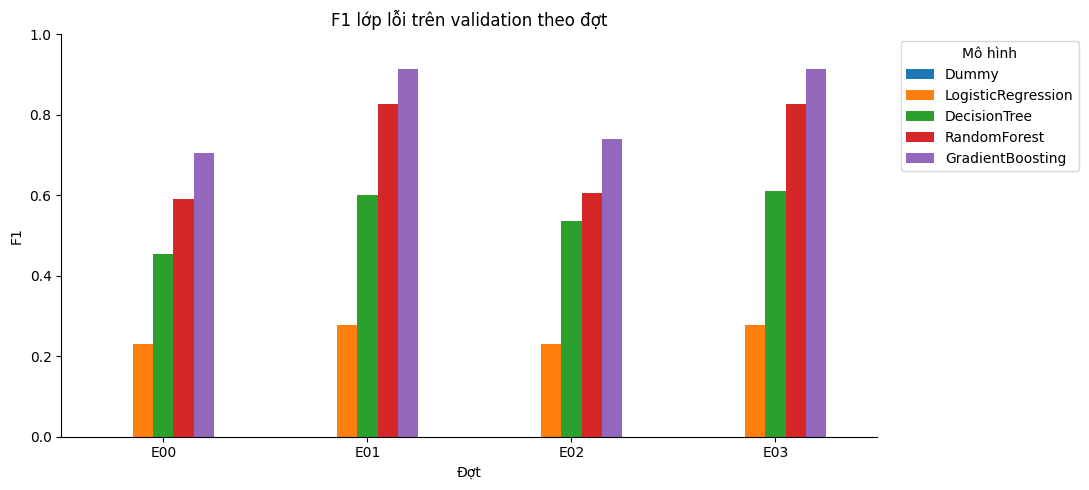

In [10]:
round_order = ["E00", "E01", "E02", "E03"]
model_order = ["Dummy", "LogisticRegression", "DecisionTree", "RandomForest", "GradientBoosting"]
f1_table = log.pivot(index="run", columns="model", values="f1").reindex(round_order)
f1_table = f1_table.reindex(columns=[name for name in model_order if name in f1_table.columns])
ax = f1_table.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0)
ax.set(title="F1 lớp lỗi trên validation theo đợt", xlabel="Đợt", ylabel="F1")
ax.legend(title="Mô hình", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Nhận xét biểu đồ F1

F1 cao nhất trên validation nằm ở E01 và E03. So với E00, E02 tăng F1 ở cả bốn mô hình; tuy vậy mức F1 của E02 vẫn thấp hơn E01/E03 ở lần chạy này. Nên cân nhắc cả FN/FP và mục tiêu phát hiện lỗi thay vì chọn mô hình chỉ theo một chỉ số.

## 6. Kết luận

- Dữ liệu AI4I có nhãn lỗi hiếm; vì vậy accuracy đơn lẻ không đủ để đánh giá khả năng phát hiện lỗi.
- Xem các bảng và biểu đồ train để nhận biết phân bố, nhưng không xem tương quan là nguyên nhân gây lỗi.
- So sánh mô hình dựa trên precision/recall/F1 cùng số FN/FP trên validation; đánh giá cuối trên test vẫn cần được thực hiện riêng sau khi chốt phương án.
- Các cờ mode có thể dùng đối chiếu chất lượng nhãn nhưng phải loại khỏi đầu vào mô hình vì chúng tiết lộ trực tiếp thông tin liên quan đến nhãn.